In [16]:
import cdsapi
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

In [7]:
dataset = "reanalysis-era5-single-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "year": [
        "1979", "1980", "1981",
        "1982", "1983", "1984",
        "1985", "1986", "1987",
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024"
    ],
    "month": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12"
    ],
    "time": ["00:00"],
    "data_format": "grib",
    "download_format": "unarchived",
    "variable": [
        "sea_surface_temperature",
        "total_column_rain_water"
    ],
    "area": [65, 120, -65, -60]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()


2025-10-16 11:51:32,273 INFO Request ID is 3205b513-0738-4fa5-8267-d530fe2c1bf7
2025-10-16 11:51:32,477 INFO status has been updated to accepted
2025-10-16 11:51:41,658 INFO status has been updated to running
2025-10-16 11:53:28,063 INFO status has been updated to successful


'467b3d22b9b1d0ecb3d506c52fa27b35.grib'

In [8]:
ds = xr.open_dataset('467b3d22b9b1d0ecb3d506c52fa27b35.grib', engine = 'cfgrib')

c:\Users\12ian\anaconda3\envs\ATMS523-env\Lib\site-packages\cfgrib\xarray_plugin.py:132: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


In [9]:
ds

<xarray.Dataset> Size: 2GB
Dimensions:     (time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B ...
  * time        (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    valid_time  (time) datetime64[ns] 4kB ...
Data variables:
    sst         (time, latitude, longitude) float32 829MB ...
    tcrw        (time, latitude, longitude) float32 829MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-16T11:54 GRIB to CDM+CF via cfgrib-0.9.1...

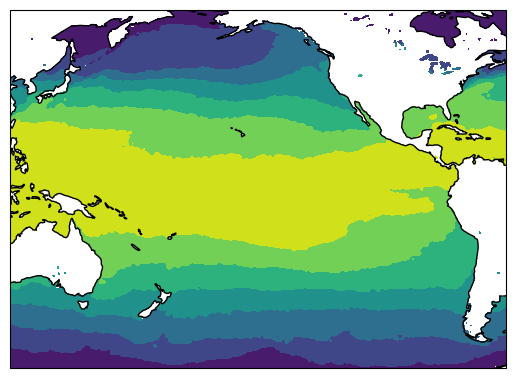

In [30]:
snapshot = ds['sst'].isel(time = 100).values

lat_grid, lon_grid = np.meshgrid(ds.longitude.values, ds.latitude.values)

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree(central_longitude=-180)})
ax.contourf(lat_grid, lon_grid, snapshot, transform = ccrs.PlateCarree())
ax.coastlines()


In [21]:
snapshot.shape

(521, 721)